In [2]:
import pandas as pd
import numpy as np

# Загрузка датасета

In [3]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv', sep=',')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Описание столбцов

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## Удаление дубликатов

In [6]:
df.shape

(7043, 21)

In [7]:
df = df.drop_duplicates()
df.shape

(7043, 21)

## Заполнение пропусков

In [8]:
categories = df.columns.to_list()
print(categories)

categories_values = df[['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']].values.ravel()
unique_values = pd.unique(categories_values)

print(unique_values)

df = df.replace({"MultipleLines": 'No phone service',
                "OnlineSecurity": 'No internet service',
                "OnlineBackup": 'No internet service',
                "DeviceProtection": 'No internet service',
                "TechSupport": 'No internet service',
                "StreamingTV": 'No internet service',
                'StreamingMovies': 'No internet service'}, 'No')

df[['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']].head()

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
['No phone service' 'No' 'Yes' 'No internet service']


,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,No,No,Yes,No,No,No,No
1,No,Yes,No,Yes,No,No,No
2,No,Yes,Yes,No,No,No,No
3,No,Yes,No,Yes,Yes,No,No
4,No,No,No,No,No,No,No


In [9]:
df.isnull().mean() * 100

customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64

## matplotlib и seaborn

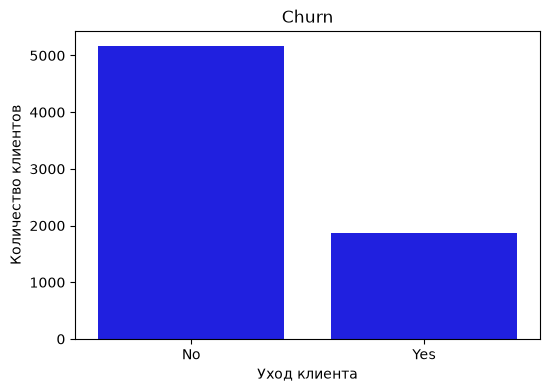

Churn
No     517400
Yes    186900
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, color='blue')
plt.title('Отток')
plt.xlabel('Уход клиента')
plt.ylabel('Количество клиентов')
plt.show()

print((df['Churn'].value_counts() * 100).round(2))

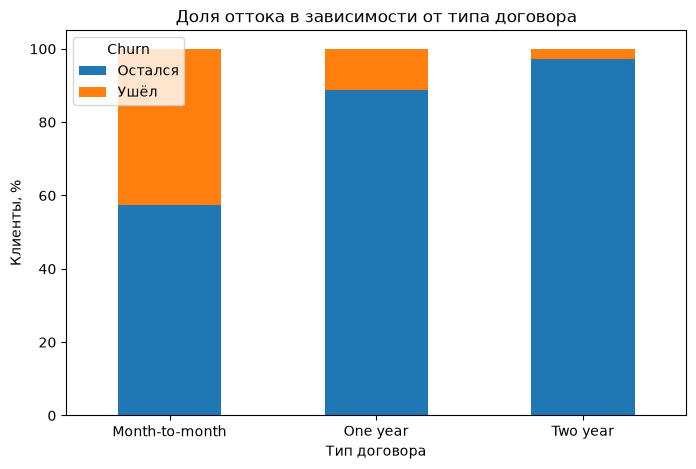

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [11]:
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
contract_churn = contract_churn[['No', 'Yes']]

contract_churn.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title('Доля оттока в зависимости от типа договора')
plt.xlabel('Тип договора')
plt.ylabel('Клиенты, %')
plt.legend(title='Churn', labels=['Остался', 'Ушёл'])
plt.xticks(rotation=0)
plt.show()

contract_churn.round(2)

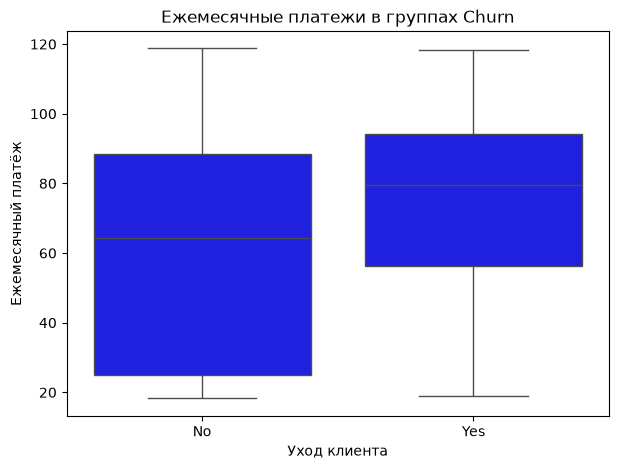

In [14]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, color='blue')
plt.title('Ежемесячные платежи в группах Churn')
plt.xlabel('Уход клиента')
plt.ylabel('Ежемесячный платёж')
plt.show()

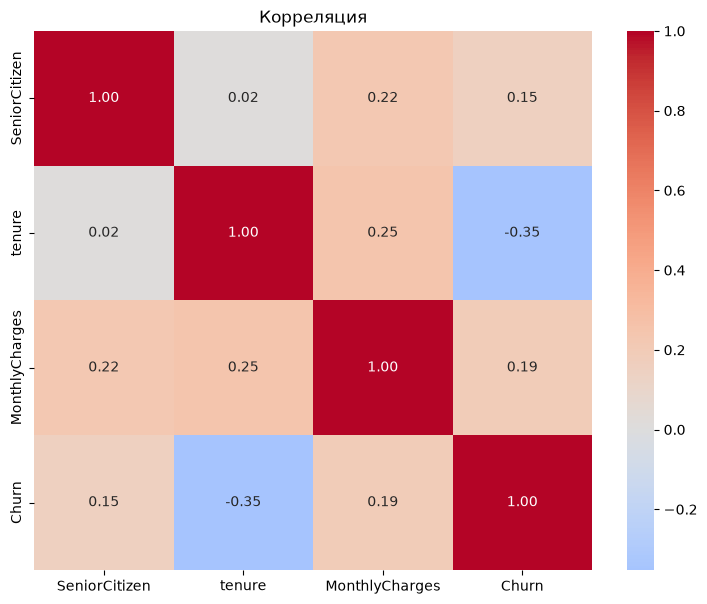

Churn             1.000000
MonthlyCharges    0.193356
SeniorCitizen     0.150889
tenure           -0.352229
Name: Churn, dtype: float64

In [19]:
corr_df = df.copy()
corr_df['Churn'] = corr_df['Churn'].map({'No': 0, 'Yes': 1})

corr_matrix = corr_df.select_dtypes(include=['number']).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляция')
plt.show()

corr_matrix['Churn'].sort_values(ascending=False)

In [16]:
print('Размер датасета до удаления дубликатов:', df.shape)
print('Полных дубликатов:', df.duplicated().sum())
print('Дубликатов customerID:', df['customerID'].duplicated().sum())

df_clean = df.drop_duplicates().copy()
df_clean = df_clean.drop_duplicates(subset='customerID', keep='first')

print('Размер датасета после удаления дубликатов:', df_clean.shape)

Размер датасета до удаления дубликатов: (7043, 21)
Полных дубликатов: 0
Дубликатов customerID: 0
Размер датасета после удаления дубликатов: (7043, 21)
